# Charts of the answers without and with retrieval (KAN-99)
Gözde Nur Özdemir · ELIZA · Sprint 2

**What this notebook does:** it draws the charts of `src/rag_vs_no_rag.ipynb` and saves them in `docs/eval/answers-results.pdf`, like the PDF of the embedding experiment. It needs no model: it reads the saved answers in `docs/eval/answers/` (Claude Haiku 5.5 with the whole text, and our system, Llama-3.1-8B with 8 chunks), runs the same automatic checks again and draws the charts. The last cell can add the PDF and the charts to the W&B run of `src/rag_vs_no_rag.ipynb`.

**How to run:** from `src/`, *Run all* (CPU, a few seconds), or in Colab (it downloads the repository first).

In [1]:
import os, subprocess, sys
if "google.colab" in sys.modules:
    REPO = "/content/ELIZA_DI502_ORGANIZATION"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "https://github.com/ELIZA-DI502/ELIZA_DI502_ORGANIZATION.git", REPO], check=True)
    os.chdir(REPO + "/src")

## 1. The answers and the questions

In [2]:
import csv, json, re
import numpy as np, pandas as pd
pd.set_option("display.max_colwidth", None)
chunks = [json.loads(line) for line in open("../data/chunks.jsonl", encoding="utf-8")]
by_chunk = {c["chunk_id"]: c for c in chunks}
val = list(csv.DictReader(open("../docs/eval/eval-set-v1-val.csv", encoding="utf-8-sig")))       # test is never opened
by_id = {q["id"]: q for q in val}
reference = {r["provision_id"]: r["reference"] for r in csv.DictReader(open("../data/provision-list.csv", encoding="utf-8"))}
full_text = pd.read_csv("../docs/eval/answers/val-full-text-claude-haiku-5-5.csv", dtype=str).fillna("")
with_retrieval = pd.read_csv("../docs/eval/answers/val-with-retrieval-llama-3-1-8b.csv", dtype=str).fillna("")
with_retrieval["seconds"] = with_retrieval["seconds"].astype(float)
assert set(full_text["id"]) == set(with_retrieval["id"]) == set(by_id)
print(len(val), "val questions;", full_text["model"].iloc[0], "and", with_retrieval["model"].iloc[0])

30 val questions; Claude Haiku 5.5 (claude.ai chat) and hf.co/bartowski/Meta-Llama-3.1-8B-Instruct-GGUF:Q4_K_M


## 2. The automatic checks
The same code as step 5 of `src/rag_vs_no_rag.ipynb`, so the numbers are the same.

In [3]:
CITE = re.compile(r"(Article\s+\d+[a-z]?(?:\s*\(\d+\))?(?:,?\s*(?:first|second|third|fourth|fifth)\s+subparagraph)?(?:,?\s*point)?(?:\s*\([a-z0-9]+\))*|Annex\s+[IVX]+(?:,?\s*point\s*\d+(?:\s*\([a-z]\))?)?)", re.I)

def norm(ref):
    """One spelling for a reference: 'Article 6(3), second subparagraph, point (a)' and 'Article 6(3)(a)' -> 'article6(3)(a)'."""
    ref = ref.lower()
    ref = re.sub(r"(first|second|third|fourth|fifth) subparagraph", "", ref)
    for n, word in enumerate(["first", "second", "third", "fourth"], 1):        # Article 113, third paragraph = Article 113(3)
        ref = ref.replace(f", {word} paragraph", f"({n})")
    return re.sub(r"[\s,]|point|paragraph", "", ref)

def check(qid, answer, retrieved=""):
    """The automatic checks of one answer to question qid; retrieved: its chunk IDs separated by ";" (with retrieval only).
    Returns a dict: the cited references and True/False for each check."""
    q = by_id[qid]
    cited = sorted({norm(c) for c in CITE.findall(answer)})
    gold = [norm(reference[p]) for p in q["gold_ids"].split(";") if p in reference] if q["gold_ids"].strip() else []
    out = {"cited": "; ".join(cited), "cites a provision": bool(cited),
           "says the text does not answer": "does not answer this question" in answer}
    if gold:
        out["expected provision cited (strict)"] = any(c == g for c in cited for g in gold)
        out["expected provision cited (lenient)"] = any(g.startswith(c) for c in cited for g in gold)
    if retrieved and cited:
        allowed = [norm(by_chunk[c]["ref"]) for c in retrieved.split(";")]
        out["cites only retrieved chunks"] = all(any(a.startswith(c) or c.startswith(a) for a in allowed) for c in cited)
    return out

rows = []
for _, r in full_text.iterrows():
    rows.append({"id": r["id"], "side": "without retrieval (Claude Haiku 5.5, full text)", "answer": r["answer"], **check(r["id"], r["answer"])})
for _, r in with_retrieval.iterrows():
    rows.append({"id": r["id"], "side": "with retrieval (Llama-3.1-8B, 8 chunks)", "answer": r["answer"], "seconds": r["seconds"],
                 "retrieved": r["retrieved"], **check(r["id"], r["answer"], r["retrieved"])})
answers = pd.DataFrame(rows)
for col in ["type", "expected_behaviour", "gold_ids"]:
    answers[col] = answers["id"].map(lambda i: by_id[i][col])

CHECKS = ["cites a provision", "expected provision cited (strict)", "expected provision cited (lenient)",
          "cites only retrieved chunks", "says the text does not answer"]
summary = answers.groupby("side")[CHECKS].apply(lambda d: d.astype(float).mean()).round(2).T
summary.loc["questions"] = answers.groupby("side").size()
summary

side,"with retrieval (Llama-3.1-8B, 8 chunks)","without retrieval (Claude Haiku 5.5, full text)"
cites a provision,0.77,0.97
expected provision cited (strict),0.67,0.78
expected provision cited (lenient),0.70,0.81
cites only retrieved chunks,0.83,NaN
says the text does not answer,0.33,0.03
questions,30.00,30.00


## 3. Retrieval: Recall@8 and Recall@5
The 8 chunks of every answer with retrieval are saved in their ranked order, so the retrieval scores of `src/embedding.ipynb` can be computed again here, question by question: Recall@8 for the 8 chunks the model got, and Recall@5 for the first 5 of them (D6 criterion 5). They must match run `v7g5hhxh` (0.59 and 0.43).

In [4]:
def recall_at(qid, retrieved, k):
    """Share of the gold provisions of question qid among the first k retrieved chunks (chunk ID -> provision ID)."""
    gold = set(by_id[qid]["gold_ids"].split(";"))
    found = {c.split("#")[0] for c in retrieved.split(";")[:k]}
    return len(gold & found) / len(gold)

retrieval = pd.DataFrame([{"id": r["id"], "gold": len(by_id[r["id"]]["gold_ids"].split(";")),
                           "Recall@5": round(recall_at(r["id"], r["retrieved"], 5), 2),
                           "Recall@8": round(recall_at(r["id"], r["retrieved"], 8), 2)}
                          for _, r in with_retrieval.iterrows() if by_id[r["id"]]["gold_ids"].strip()])
RECALL = retrieval[["Recall@5", "Recall@8"]].mean().round(2)
print(f"{len(retrieval)} val questions with gold provisions: Recall@5 {RECALL['Recall@5']}, Recall@8 {RECALL['Recall@8']}")
retrieval

27 val questions with gold provisions: Recall@5 0.43, Recall@8 0.59


,id,gold,Recall@5,Recall@8
0,A-01,5,0.40,0.40
1,A-02,1,1.00,1.00
2,A-05,3,0.33,0.33
3,A-06,3,0.33,0.67
4,B-01,4,0.50,0.50
5,B-03,2,1.00,1.00
6,B-04,1,1.00,1.00
7,B-05,9,0.11,0.11
8,B-06,2,0.00,0.00
9,B-07,2,0.50,1.00


## 4. Charts and PDF

Saved ../docs/eval/answers-results.pdf with 6 pages


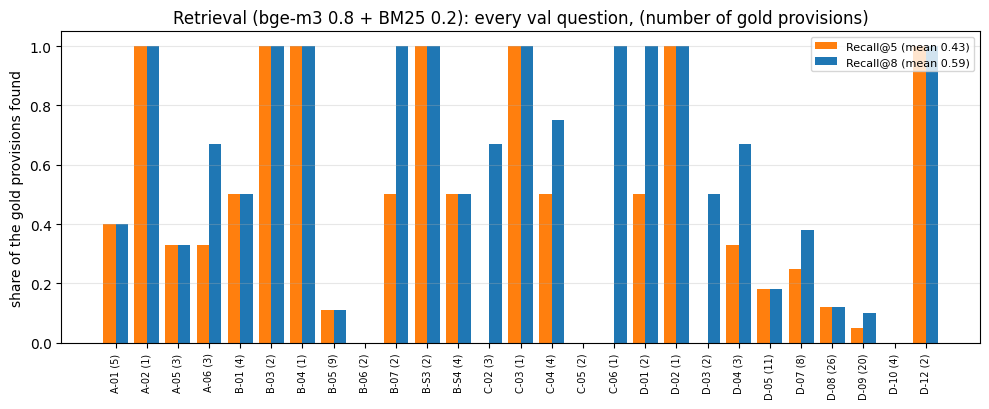

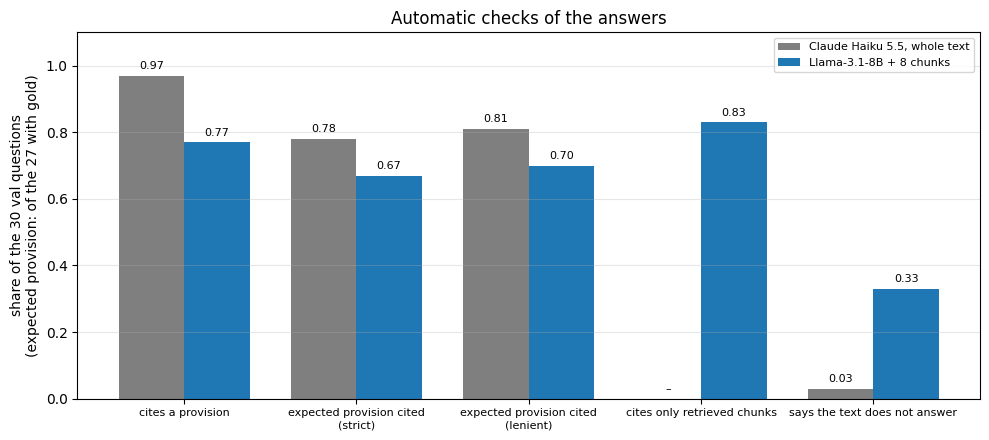

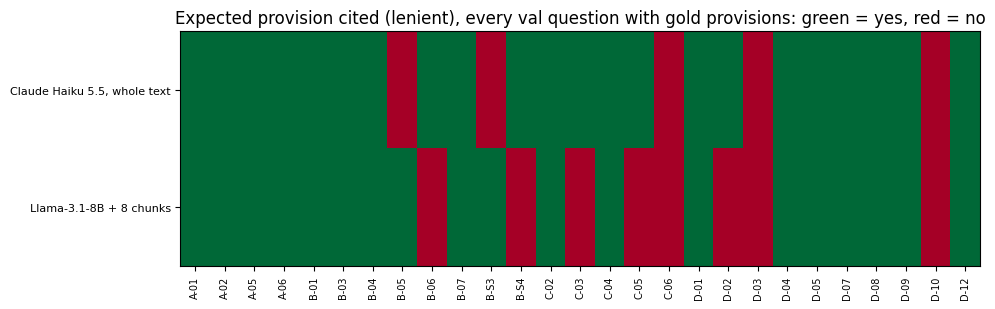

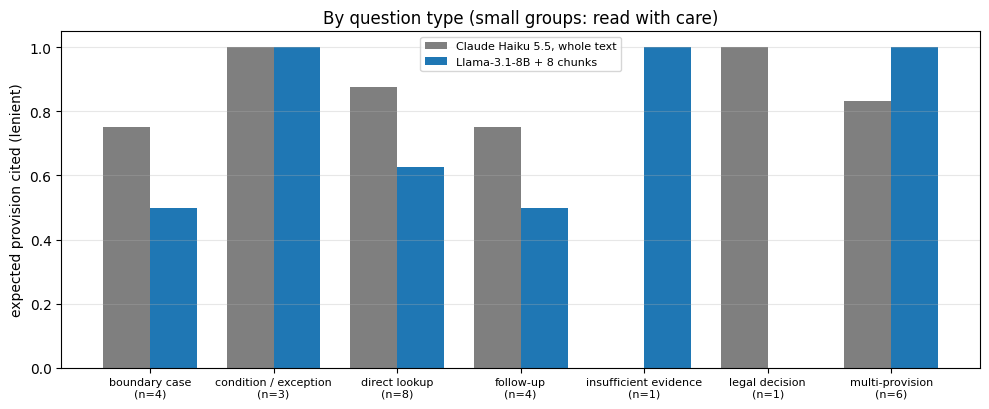

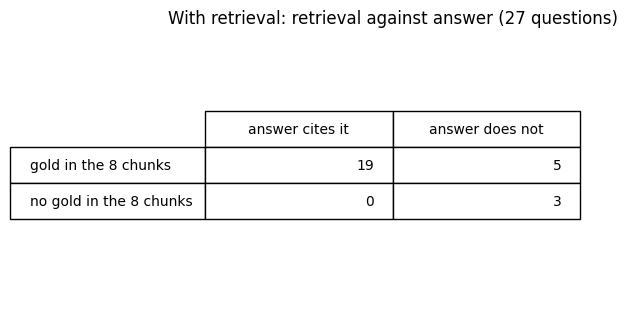

In [5]:
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

PDF_FILE = "../docs/eval/answers-results.pdf"
SIDES = ["without retrieval (Claude Haiku 5.5, full text)", "with retrieval (Llama-3.1-8B, 8 chunks)"]
SHORT = {SIDES[0]: "Claude Haiku 5.5, whole text", SIDES[1]: "Llama-3.1-8B + 8 chunks"}
COLOURS = {SIDES[0]: "tab:grey", SIDES[1]: "tab:blue"}
figures = {}

# 0. retrieval: Recall@5 and Recall@8, every val question with gold provisions
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(retrieval)); width = 0.4
ax.bar(x - width / 2, retrieval["Recall@5"], width, label=f"Recall@5 (mean {RECALL['Recall@5']:.2f})", color="tab:orange")
ax.bar(x + width / 2, retrieval["Recall@8"], width, label=f"Recall@8 (mean {RECALL['Recall@8']:.2f})", color="tab:blue")
ax.set_xticks(x); ax.set_xticklabels([f"{i} ({g})" for i, g in zip(retrieval["id"], retrieval["gold"])], rotation=90, fontsize=7)
ax.set_ylim(0, 1.05); ax.set_ylabel("share of the gold provisions found")
ax.set_title("Retrieval (bge-m3 0.8 + BM25 0.2): every val question, (number of gold provisions)"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3); fig.tight_layout()
figures["retrieval_recall"] = fig

# 1. the checks, both sides
fig, ax = plt.subplots(figsize=(10, 4.5))
rows = [c for c in CHECKS if summary.loc[c].notna().any()]
x = np.arange(len(rows)); width = 0.38
for n, side in enumerate(SIDES):
    values = [summary.loc[c, side] if pd.notna(summary.loc[c, side]) else 0 for c in rows]
    bars = ax.bar(x + (n - 0.5) * width, values, width, label=SHORT[side], color=COLOURS[side])
    for b, v, c in zip(bars, values, rows):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, "–" if pd.isna(summary.loc[c, side]) else f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([r.replace(" (", "\n(") for r in rows], fontsize=8)
ax.set_ylim(0, 1.1); ax.set_ylabel("share of the 30 val questions\n(expected provision: of the 27 with gold)")
ax.set_title("Automatic checks of the answers"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3); fig.tight_layout()
figures["answers_checks"] = fig

# 2. expected provision cited, question by question
scored_ids = [q["id"] for q in val if q["gold_ids"].strip()]
grid = answers[answers["id"].isin(scored_ids)].pivot(index="id", columns="side", values="expected provision cited (lenient)").reindex(scored_ids)[SIDES]
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.imshow(grid.T.astype(float).values, cmap="RdYlGn", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(grid))); ax.set_xticklabels(grid.index, rotation=90, fontsize=7)
ax.set_yticks(range(2)); ax.set_yticklabels([SHORT[s] for s in SIDES], fontsize=8)
ax.set_title("Expected provision cited (lenient), every val question with gold provisions: green = yes, red = no"); fig.tight_layout()
figures["answers_by_question"] = fig

# 3. by question type
by_type = answers[answers["id"].isin(scored_ids)].groupby(["type", "side"])["expected provision cited (lenient)"].mean().unstack()[SIDES]
counts = answers[answers["id"].isin(scored_ids) & (answers["side"] == SIDES[1])].groupby("type").size()
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(by_type))
for n, side in enumerate(SIDES):
    ax.bar(x + (n - 0.5) * width, by_type[side], width, label=SHORT[side], color=COLOURS[side])
ax.set_xticks(x); ax.set_xticklabels([f"{t}\n(n={counts[t]})" for t in by_type.index], fontsize=8)
ax.set_ylim(0, 1.05); ax.set_ylabel("expected provision cited (lenient)")
ax.set_title("By question type (small groups: read with care)"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3); fig.tight_layout()
figures["answers_by_type"] = fig

# 4. retrieval and answer: was a gold provision among the 8 chunks, and did the answer cite one?
rag = answers[(answers["side"] == SIDES[1]) & answers["id"].isin(scored_ids)].copy()
rag["gold in the 8 chunks"] = rag.apply(lambda r: bool(set(by_id[r["id"]]["gold_ids"].split(";")) & {c.split("#")[0] for c in r["retrieved"].split(";")}), axis=1)
table = pd.crosstab(rag["gold in the 8 chunks"], rag["expected provision cited (lenient)"])
fig, ax = plt.subplots(figsize=(6, 3.2)); ax.axis("off")
cells = [[str(table.loc[i, j]) if (i in table.index and j in table.columns) else "0" for j in [True, False]] for i in [True, False]]
t = ax.table(cellText=cells, rowLabels=["gold in the 8 chunks", "no gold in the 8 chunks"], colLabels=["answer cites it", "answer does not"], loc="center")
t.scale(1, 2); ax.set_title("With retrieval: retrieval against answer (27 questions)"); fig.tight_layout()
figures["retrieval_vs_answer"] = fig

# all in one PDF, the first page with the setting and the main numbers
with PdfPages(PDF_FILE) as pdf:
    fig = plt.figure(figsize=(10, 4.5))
    fig.text(0.05, 0.9, "ELIZA · answers without and with retrieval on the val split (KAN-99)", fontsize=14, weight="bold")
    lines = [f"Val questions: {len(val)} ({len(scored_ids)} with gold provisions); the test split is not used",
             f"Retrieval (bge-m3 0.8 + BM25 0.2, 8 chunks): Recall@8 {RECALL['Recall@8']:.2f}, Recall@5 {RECALL['Recall@5']:.2f} (W&B run v7g5hhxh)",
             f"Without retrieval: {full_text['model'].iloc[0]}, {full_text['date'].iloc[0]}, whole consolidated text of 27/07/2026 in the chat",
             f"With retrieval: Llama-3.1-8B-Instruct Q4_K_M (Ollama 0.40.15), 8 chunks of bge-m3 0.8 + BM25 0.2, temperature 0",
             "Expected provision cited (lenient): " + ", ".join(f"{SHORT[s]} {summary.loc['expected provision cited (lenient)', s]:.2f}" for s in SIDES),
             "Cites a provision: " + ", ".join(f"{SHORT[s]} {summary.loc['cites a provision', s]:.2f}" for s in SIDES)
             + f"; with retrieval, cites only its 8 chunks: {summary.loc['cites only retrieved chunks', SIDES[1]]:.2f}",
             "Says the text does not answer: " + ", ".join(f"{SHORT[s]} {summary.loc['says the text does not answer', s]:.2f}" for s in SIDES)]
    for n, line in enumerate(lines):
        fig.text(0.05, 0.78 - n * 0.1, line, fontsize=9.5)
    pdf.savefig(fig); plt.close(fig)
    for f in figures.values():
        pdf.savefig(f)
print("Saved", PDF_FILE, "with", len(figures) + 1, "pages")


## 5. W&B (optional)
Adds the PDF and the charts to the run of `src/rag_vs_no_rag.ipynb`. Set `LOG_TO_WANDB = True` and run this cell; it asks for the key.

In [6]:
LOG_TO_WANDB = True
RUN_ID = "lgogwegq"      # the run of src/rag_vs_no_rag.ipynb
if LOG_TO_WANDB:
    import wandb
    wandb.login()
    run = wandb.init(project="eliza-rag", id=RUN_ID, resume="must")
    run.log({"charts/" + name: wandb.Image(f) for name, f in figures.items()})
    run.log({"retrieval/Recall@8": float(RECALL["Recall@8"]), "retrieval/Recall@5": float(RECALL["Recall@5"]),
             "tables/retrieval_per_question": wandb.Table(dataframe=retrieval)})
    artifact = wandb.Artifact("answers-results", type="report"); artifact.add_file(PDF_FILE); run.log_artifact(artifact)
    print("Run:", run.url); wandb.finish()

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: gozdenur104 (gozdenur104-metu-middle-east-technical-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Run: https://wandb.ai/gozdenur104-metu-middle-east-technical-university/eliza-rag/runs/lgogwegq


retrieval/Recall@5,▁
retrieval/Recall@8,▁
retrieval/Recall@5,0.43
retrieval/Recall@8,0.59
"with retrieval (Llama-3.1-8B, 8 chunks)/cites a provision",0.77
"with retrieval (Llama-3.1-8B, 8 chunks)/cites only retrieved chunks",0.83
"with retrieval (Llama-3.1-8B, 8 chunks)/expected provision cited (lenient)",0.7
"with retrieval (Llama-3.1-8B, 8 chunks)/expected provision cited (strict)",0.67
"with retrieval (Llama-3.1-8B, 8 chunks)/questions",30
"with retrieval (Llama-3.1-8B, 8 chunks)/says the text does not answer",0.33
"without retrieval (Claude Haiku 5.5, full text)/cites a provision",0.97
